### Data Acquisition

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

sns.set_theme(style="whitegrid")

In [3]:
df = pd.read_csv("iris.csv")


### Data Preproccessing

In [4]:
df.shape


(150, 5)

In [5]:
df.head()


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [6]:
df.tail()

,sepal_length,sepal_width,petal_length,petal_width,species
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica
149,5.9,3.0,5.1,1.8,virginica


In [7]:
df.describe()


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [8]:
df["species"].value_counts()


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [9]:
df.isnull().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

### Exploratory Pairplot

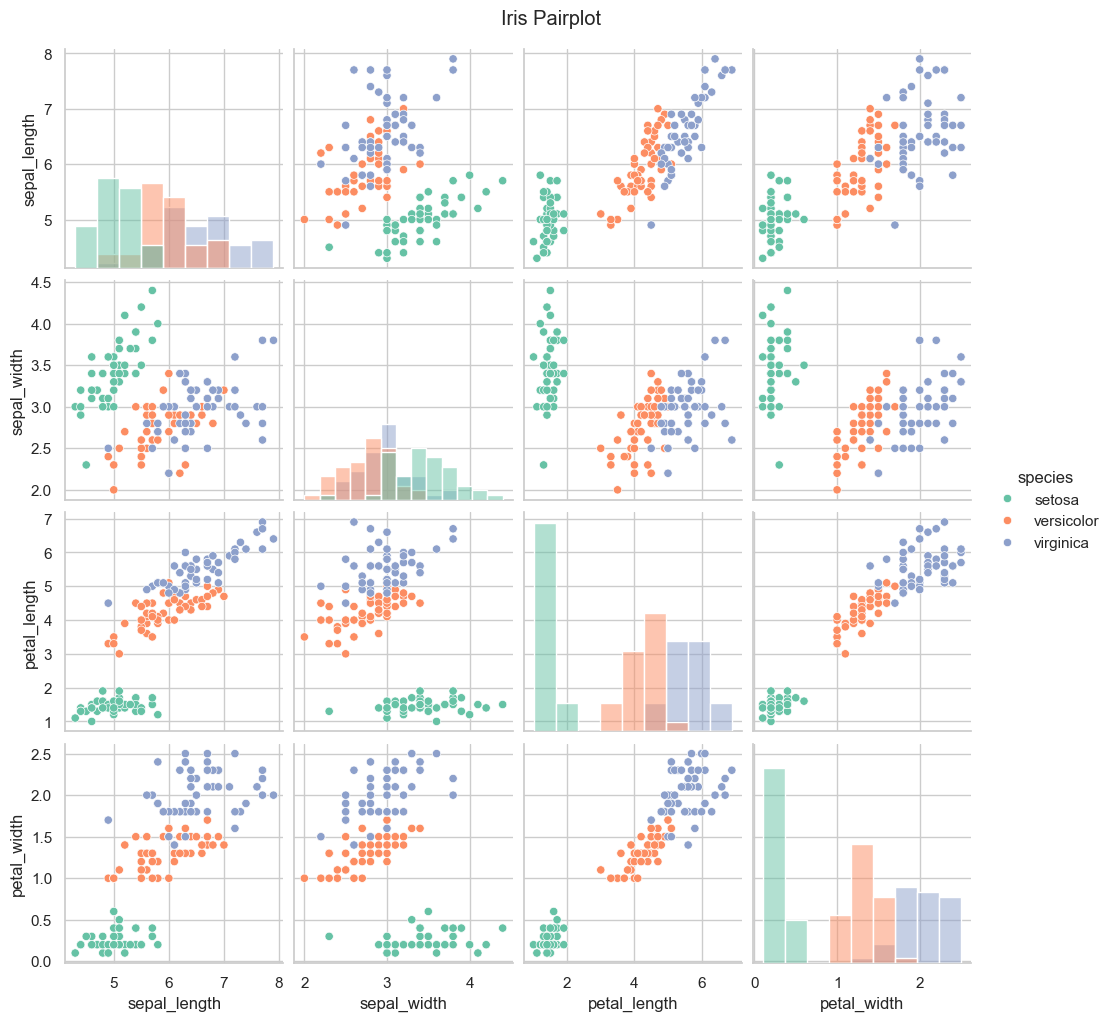

In [11]:
sns.pairplot(df, hue="species", diag_kind="hist", palette="Set2")
plt.suptitle("Iris Pairplot", y=1.02)
plt.show()

### Training / Testing data splitting

In [12]:
X = df.drop(columns="species")
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(120, 4) (30, 4)


### scaling the features

In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   
X_test_scaled = scaler.transform(X_test)         

### Training both the models together

In [14]:
log_reg = LogisticRegression(max_iter=200, random_state=42)
tree = DecisionTreeClassifier(max_depth=3, random_state=42)

log_reg.fit(X_train_scaled, y_train)
tree.fit(X_train_scaled, y_train)

models = {"Logistic Regression": log_reg, "Decision Tree": tree}
preds = {name: m.predict(X_test_scaled) for name, m in models.items()}

### Classification Report for both models

In [15]:
for name, y_pred in preds.items():
    print(f"===== {name} =====")
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
    print(classification_report(y_test, y_pred))

===== Logistic Regression =====
Accuracy: 0.9333

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

===== Decision Tree =====
Accuracy: 0.9667

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



### Confusion Matrix heatmaps

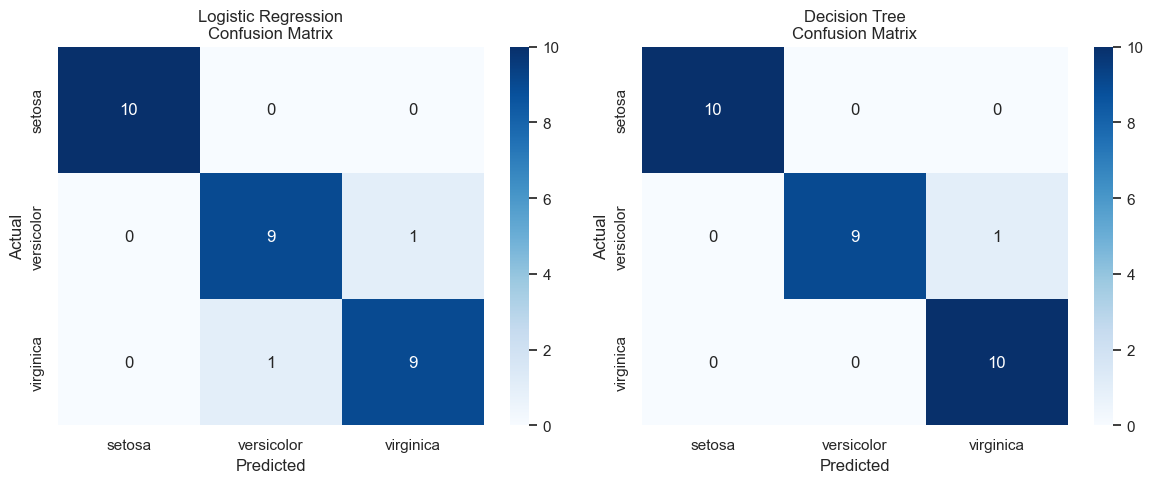

In [16]:
labels = sorted(y.unique())
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, y_pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, y_pred, labels=labels)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(f"{name}\nConfusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

### Benchmark comparison table

,Accuracy,Precision,Recall,F1-Score
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9667,0.9697,0.9667,0.9666


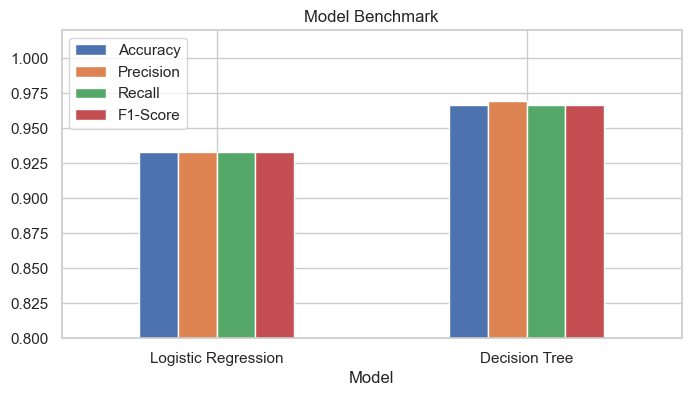

In [17]:
results = []
for name, y_pred in preds.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="weighted"),
        "Recall": recall_score(y_test, y_pred, average="weighted"),
        "F1-Score": f1_score(y_test, y_pred, average="weighted"),
    })

results_df = pd.DataFrame(results).set_index("Model").round(4)
display(results_df)

results_df.plot(kind="bar", figsize=(8, 4), ylim=(0.8, 1.02), rot=0)
plt.title("Model Benchmark")
plt.show()

### Decision boundary visualization.

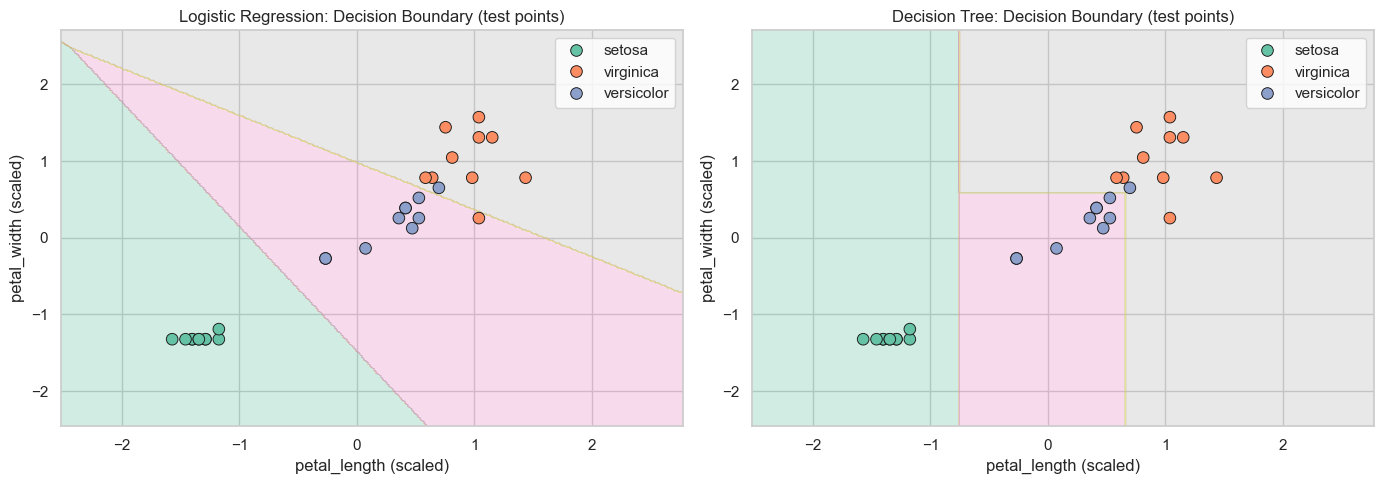

In [18]:
features_2d = ["petal_length", "petal_width"]
le = LabelEncoder()
y_enc = le.fit_transform(y)

Xtr, Xte, ytr, yte = train_test_split(
    df[features_2d], y_enc, test_size=0.2, random_state=42, stratify=y_enc
)
sc2 = StandardScaler()
Xtr_s = sc2.fit_transform(Xtr)
Xte_s = sc2.transform(Xte)

models_2d = {
    "Logistic Regression": LogisticRegression(max_iter=200, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=42),
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x_min, x_max = Xtr_s[:, 0].min() - 1, Xtr_s[:, 0].max() + 1
y_min, y_max = Xtr_s[:, 1].min() - 1, Xtr_s[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min, y_max, 300))

for ax, (name, model) in zip(axes, models_2d.items()):
    model.fit(Xtr_s, ytr)
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="Set2")
    sns.scatterplot(x=Xte_s[:, 0], y=Xte_s[:, 1],
                    hue=le.inverse_transform(yte), palette="Set2",
                    edgecolor="k", s=70, ax=ax)
    ax.set_title(f"{name}: Decision Boundary (test points)")
    ax.set_xlabel("petal_length (scaled)")
    ax.set_ylabel("petal_width (scaled)")

plt.tight_layout()
plt.show()

## Conclusion

**Which model did better?**
The Decision Tree scored a little higher. It got **96.67%** accuracy (29 out of 30 flowers right). Logistic Regression got **93.33%** (28 out of 30 right). The gap is only **3.33 percentage points**, which is just one flower.

**Which species got mixed up?**
*Setosa* was never wrong. Both models got all 10 setosa flowers right, because setosa looks very different from the other two (we could see this in the pairplot).
The mistakes were all between *versicolor* and *virginica*, because their petal sizes overlap a little.
- Logistic Regression made 2 mistakes: 1 versicolor was called virginica, and 1 virginica was called versicolor.
- Decision Tree made 1 mistake: 1 versicolor was called virginica.

**Why does scaling matter?**
The four measurements are on slightly different ranges. Logistic Regression is sensitive to this. If one feature has bigger numbers, it can have too much influence, and the model can learn slower or worse. `StandardScaler` puts all features on the same scale (mean 0, spread 1), so they are treated fairly. A Decision Tree only asks "is this value bigger or smaller than a number?", so it does not care about scale. We scaled for both anyway, so the comparison is fair.
